# Support Vector Machines - Exercise 1

In this exercise, we'll be using support vector machines (SVMs) to build a spam classifier.  We'll start with SVMs on some simple 2D data sets to see how they work.  Then we'll do some pre-processing work on a set of raw emails and build a classifier on the processed emails using a SVM to determine if they are spam or not.

The first thing we're going to do is look at a simple 2-dimensional data set and see how a linear SVM works on the data set for varying values of C (similar to the regularization term in linear/logistic regression).  Let's load the data.
## Exercise 1
#### 1. Load libraries

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from sklearn.svm import LinearSVC, SVC

#### 2. Load data
Load the file *ejer_1_data1.mat*. Find the way for loading this kind of file. **scipy.io.loadmat**

In [13]:
data1 = loadmat("data/ejer_1_data1.mat")
print({key: value.shape for key, value in data1.items() if not key.startswith("__")})

{'X': (51, 2), 'y': (51, 1)}


#### 3. Create a DataFrame with the features and target

In [14]:
X1 = data1["X"]
y1 = data1["y"].ravel().astype(int)
df1 = pd.DataFrame(X1, columns=["X1", "X2"])
df1["y"] = y1
df1.head()

,X1,X2,y
0,1.9643,4.5957,1
1,2.2753,3.8589,1
2,2.9781,4.5651,1
3,2.9320,3.5519,1
4,3.5772,2.8560,1


#### 4. Plot a scatterplot with the data

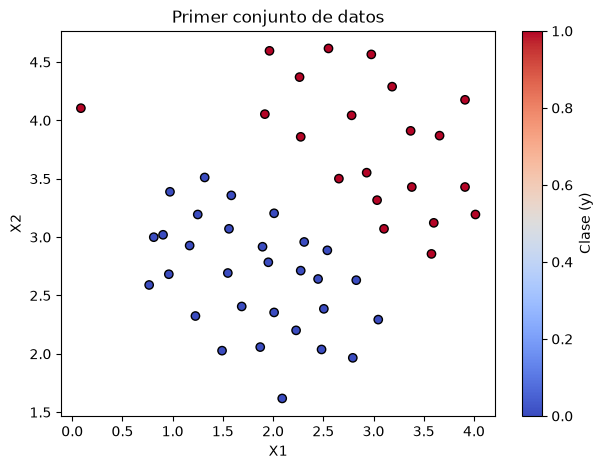

In [15]:
plt.figure(figsize=(7, 5))
plt.scatter(X1[:, 0], X1[:, 1], c=y1, cmap="coolwarm", edgecolors="black")
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Primer conjunto de datos")
plt.colorbar(label="Clase (y)")
plt.show()

Notice that there is one outlier positive example that sits apart from the others.  The classes are still linearly separable but it's a very tight fit.  We're going to train a linear support vector machine to learn the class boundary.

#### 5. LinearSVC
Declare a Linear SVC with the hyperparamenters:

```Python
LinearSVC(C=1, loss='hinge', max_iter=10000)
```

In [16]:
model1 = LinearSVC(C=1, loss="hinge", max_iter=10000)

#### 6. Try the performance (score)
For the first experiment we'll use C=1 and see how it performs.

In [17]:
model1.fit(X1, y1)
print(f"Accuracy con C=1: {model1.score(X1, y1):.2%}")

Accuracy con C=1: 98.04%


It appears that it mis-classified the outlier.

#### 7. Increase the value of C until you get a perfect classifier

In [18]:
for C in [10, 100, 1_000, 10_000]:
    model2 = LinearSVC(C=C, loss="hinge", max_iter=1_000_000, tol=1e-3)
    model2.fit(X1, y1)
    accuracy = model2.score(X1, y1)
    print(f"C={C}: accuracy={accuracy:.2%}")
    if accuracy == 1.0:
        break

print(f"Valor de C elegido: {C}")

C=10: accuracy=98.04%
C=100: accuracy=98.04%
C=1000: accuracy=100.00%
Valor de C elegido: 1000


This time we got a perfect classification of the training data, however by increasing the value of C we've created a decision boundary that is no longer a natural fit for the data.  We can visualize this by looking at the confidence level for each class prediction, which is a function of the point's distance from the hyperplane.

#### 8. Plot Decission Function
Get the `decision_function()` output for the first model. Plot a scatterplot with X1, X2 and a range of colors based on `decision_function()`

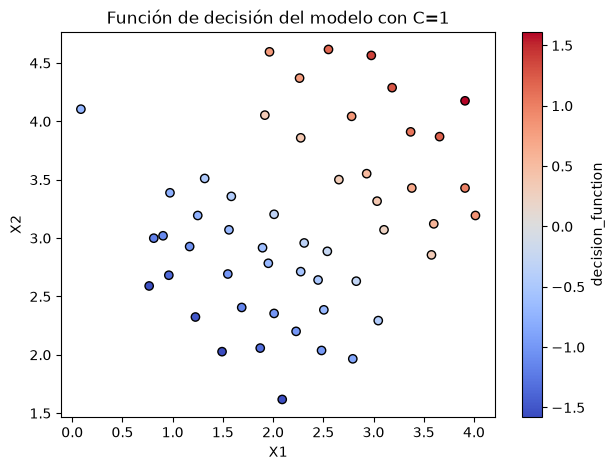

In [19]:
decision1 = model1.decision_function(X1)
plt.figure(figsize=(7, 5))
plt.scatter(X1[:, 0], X1[:, 1], c=decision1, cmap="coolwarm", edgecolors="black")
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Función de decisión del modelo con C=1")
plt.colorbar(label="decision_function")
plt.show()

#### 9. Do the same with the second model

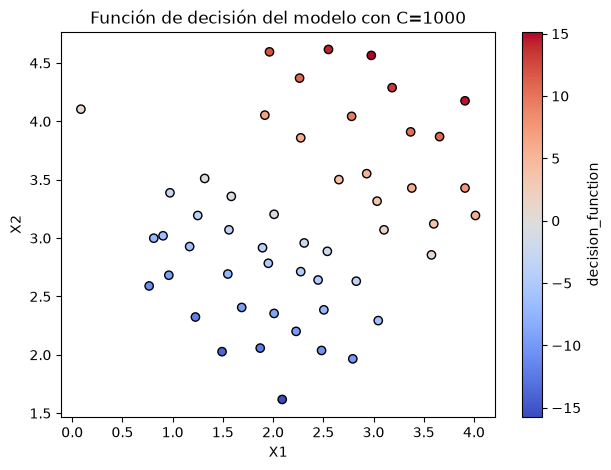

In [20]:
decision2 = model2.decision_function(X1)
plt.figure(figsize=(7, 5))
plt.scatter(X1[:, 0], X1[:, 1], c=decision2, cmap="coolwarm", edgecolors="black")
plt.xlabel("X1")
plt.ylabel("X2")
plt.title(f"Función de decisión del modelo con C={C}")
plt.colorbar(label="decision_function")
plt.show()

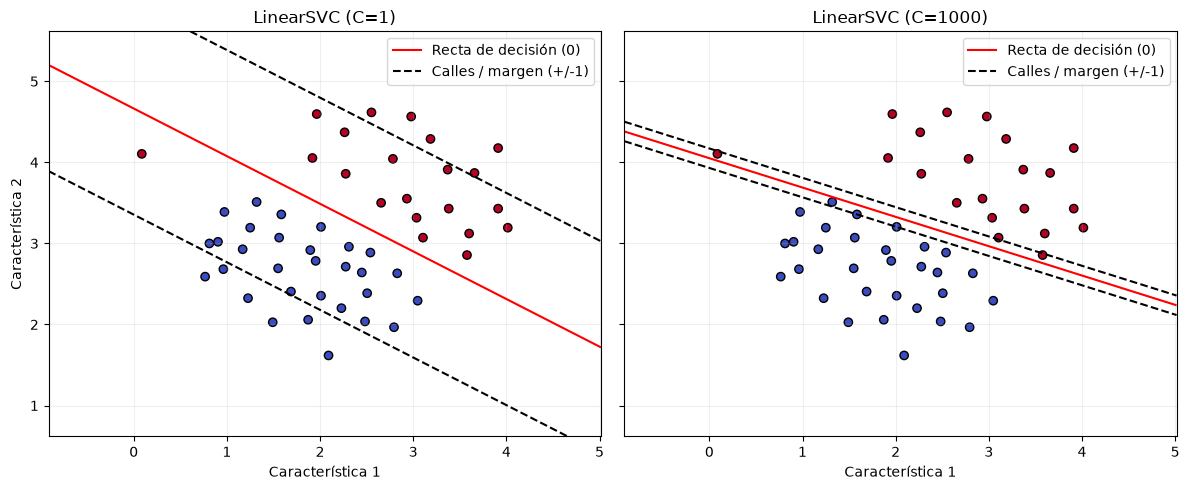

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.svm import LinearSVC

# Ajusta estos nombres si tus variables se llaman de otra manera
X = np.asarray(X1)
y = np.asarray(y1)


fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300),
)

for ax, C in zip(axes, [1, 1000]):
    modelo = LinearSVC(C=C, max_iter=10000, random_state=0)
    modelo.fit(X, y)

    puntaje = modelo.decision_function(np.c_[xx.ravel(), yy.ravel()])
    puntaje = puntaje.reshape(xx.shape)

    ax.contour(
        xx, yy, puntaje,
        levels=[-1, 0, 1],
        colors=["black", "red", "black"],
        linestyles=["--", "-", "--"],
    )
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="k")
    ax.set_title(f"LinearSVC (C={C})")
    ax.set_xlabel("Característica 1")
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Característica 2")

leyenda = [
    Line2D([0], [0], color="red", label="Recta de decisión (0)"),
    Line2D([0], [0], color="black", linestyle="--", label="Calles / margen (+/-1)"),
]
for ax in axes:
    ax.legend(handles=leyenda)

plt.tight_layout()
plt.show()

https://www.svm-tutorial.com/2015/06/svm-understanding-math-part-3/

#### 1. Load the data `ejer_1_data2.mat`

In [9]:
data2 = loadmat("data/ejer_1_data2.mat")
print({key: value.shape for key, value in data2.items() if not key.startswith("__")})

{'X': (863, 2), 'y': (863, 1)}


#### 2. Create a DataFrame with the features and target

In [13]:
X2 = data2["X"]
y2 = data2["y"].ravel().astype(int)
df2 = pd.DataFrame(X2, columns=["X1", "X2"])
df2["y"] = y2
df2.head()

,X1,X2,y
0,0.107143,0.603070,1
1,0.093318,0.649854,1
2,0.097926,0.705409,1
3,0.155530,0.784357,1
4,0.210829,0.866228,1


#### 3. Plot a scatterplot with the data

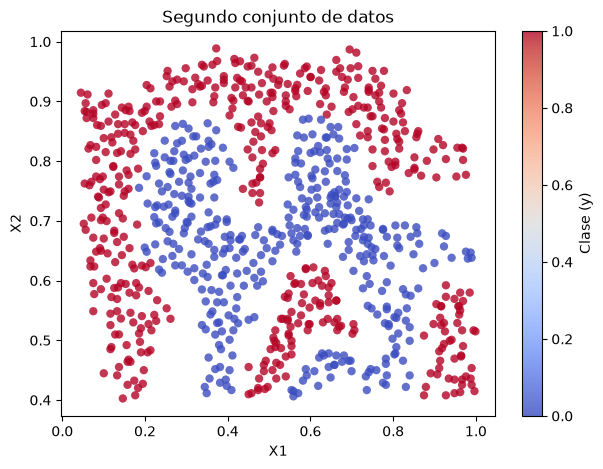

In [14]:
plt.figure(figsize=(7, 5))
plt.scatter(X2[:, 0], X2[:, 1], c=y2, cmap="coolwarm", edgecolors="none", alpha=0.8)
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Segundo conjunto de datos")
plt.colorbar(label="Clase (y)")
plt.show()

For this data set we'll build a support vector machine classifier using the built-in RBF kernel and examine its accuracy on the training data.  To visualize the decision boundary, this time we'll shade the points based on the predicted probability that the instance has a negative class label.  We'll see from the result that it gets most of them right.

#### 4. Declare a SVC with this hyperparameters
```Python
SVC(C=100, gamma=10, probability=True)
```


In [15]:
model_rbf = SVC(C=100, gamma=10, probability=True)

#### 5. Fit the classifier and get the score

In [16]:
model_rbf.fit(X2, y2)
print(f"Accuracy del SVM con kernel RBF: {model_rbf.score(X2, y2):.2%}")

Accuracy del SVM con kernel RBF: 96.99%


c:\Users\gera_\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


#### 6. Plot the scatter plot and probability of predicting 0 with a [sequential color](https://matplotlib.org/3.1.1/tutorials/colors/colormaps.html)

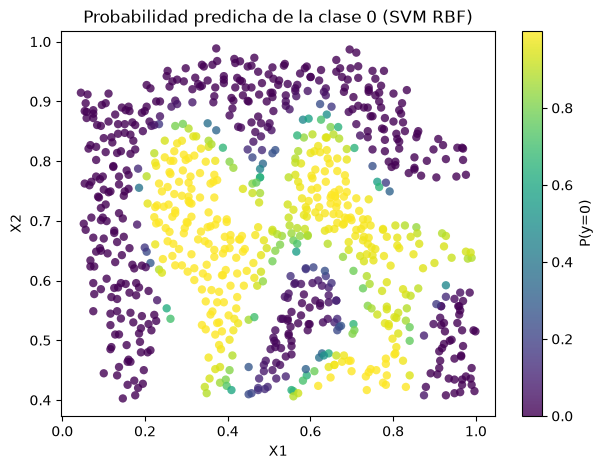

In [20]:
index_0 = np.flatnonzero(model_rbf.classes_ == 0)[0]
probability_0 = model_rbf.predict_proba(X2)[:, index_0]

plt.figure(figsize=(7, 5))
points = plt.scatter(
    X2[:, 0], X2[:, 1], c=probability_0, cmap="viridis", edgecolors="none", alpha=0.8
)
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Probabilidad predicha de la clase 0 (SVM RBF)")
plt.colorbar(points, label="P(y=0)")
plt.show()